In [1]:
# import kagglehub

# # Download latest version
# path = kagglehub.dataset_download("gorororororo23/plant-growth-data-classification")

# print("Path to dataset files:", path)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA


In [2]:
df = pd.read_csv("../../../../datasets/plant_growth_dataset/plant_growth_data.csv")

In [3]:
df

,Soil_Type,Sunlight_Hours,Water_Frequency,Fertilizer_Type,Temperature,Humidity,Growth_Milestone
0,loam,5.192294,bi-weekly,chemical,31.719602,61.591861,0
1,sandy,4.033133,weekly,organic,28.919484,52.422276,1
2,loam,8.892769,bi-weekly,none,23.179059,44.660539,0
3,loam,8.241144,bi-weekly,none,18.465886,46.433227,0
4,sandy,8.374043,bi-weekly,organic,18.128741,63.625923,0
...,...,...,...,...,...,...,...
188,sandy,5.652000,daily,none,28.000000,70.200000,0
189,clay,7.528000,weekly,chemical,30.500000,60.100000,1
190,loam,4.934000,bi-weekly,none,24.500000,61.700000,0
191,sandy,8.273000,daily,organic,27.900000,69.500000,1


In [4]:
df.columns

Index(['Soil_Type', 'Sunlight_Hours', 'Water_Frequency', 'Fertilizer_Type',
       'Temperature', 'Humidity', 'Growth_Milestone'],
      dtype='str')

In [5]:
df.head()

,Soil_Type,Sunlight_Hours,Water_Frequency,Fertilizer_Type,Temperature,Humidity,Growth_Milestone
0,loam,5.192294,bi-weekly,chemical,31.719602,61.591861,0
1,sandy,4.033133,weekly,organic,28.919484,52.422276,1
2,loam,8.892769,bi-weekly,none,23.179059,44.660539,0
3,loam,8.241144,bi-weekly,none,18.465886,46.433227,0
4,sandy,8.374043,bi-weekly,organic,18.128741,63.625923,0


In [6]:
df.tail()

,Soil_Type,Sunlight_Hours,Water_Frequency,Fertilizer_Type,Temperature,Humidity,Growth_Milestone
188,sandy,5.652,daily,none,28.0,70.2,0
189,clay,7.528,weekly,chemical,30.5,60.1,1
190,loam,4.934,bi-weekly,none,24.5,61.7,0
191,sandy,8.273,daily,organic,27.9,69.5,1
192,clay,6.732,weekly,none,21.7,56.9,0


In [7]:
df.describe(include='all')

,Soil_Type,Sunlight_Hours,Water_Frequency,Fertilizer_Type,Temperature,Humidity,Growth_Milestone
count,193,193.000000,193,193,193.000000,193.000000,193.000000
unique,3,NaN,3,3,NaN,NaN,NaN
top,clay,NaN,daily,none,NaN,NaN,NaN
freq,67,NaN,74,74,NaN,NaN,NaN
mean,NaN,6.826484,NaN,NaN,25.076087,58.098927,0.497409
std,NaN,1.599509,NaN,NaN,5.354170,12.631799,0.501294
min,NaN,4.033133,NaN,NaN,15.200000,30.567682,0.000000
25%,NaN,5.477000,NaN,NaN,20.637095,49.300000,0.000000
50%,NaN,6.833290,NaN,NaN,25.912336,59.182806,0.000000
75%,NaN,8.241144,NaN,NaN,29.757938,69.100000,1.000000


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 193 entries, 0 to 192
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Soil_Type         193 non-null    str    
 1   Sunlight_Hours    193 non-null    float64
 2   Water_Frequency   193 non-null    str    
 3   Fertilizer_Type   193 non-null    str    
 4   Temperature       193 non-null    float64
 5   Humidity          193 non-null    float64
 6   Growth_Milestone  193 non-null    int64  
dtypes: float64(3), int64(1), str(3)
memory usage: 13.9 KB


In [9]:
df.isna().sum()

Soil_Type           0
Sunlight_Hours      0
Water_Frequency     0
Fertilizer_Type     0
Temperature         0
Humidity            0
Growth_Milestone    0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.nunique()

Soil_Type             3
Sunlight_Hours      190
Water_Frequency       3
Fertilizer_Type       3
Temperature         189
Humidity            191
Growth_Milestone      2
dtype: int64

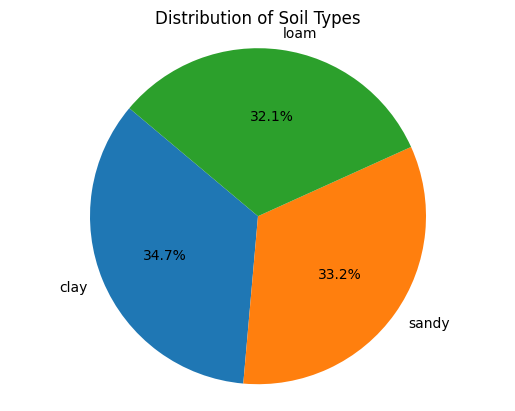

In [12]:
plt.pie(
    df['Soil_Type'].value_counts().values, 
    labels=df["Soil_Type"].value_counts().index, 
    autopct='%1.1f%%', 
    startangle=140
    )
plt.title("Distribution of Soil Types")
plt.axis('equal')
plt.show()

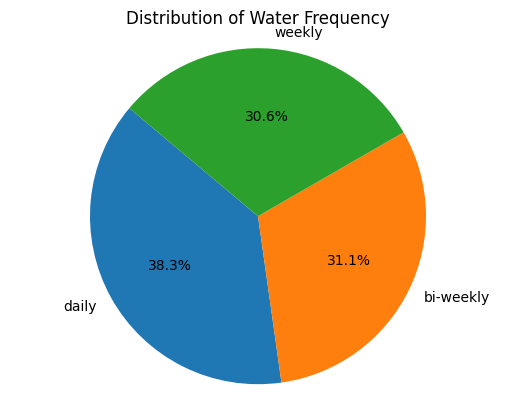

In [13]:
plt.pie(
    df["Water_Frequency"].value_counts().values,
    labels=df["Water_Frequency"].value_counts().index,
    autopct='%1.1f%%',
    startangle=140
)
plt.title("Distribution of Water Frequency")
plt.axis('equal')
plt.show()

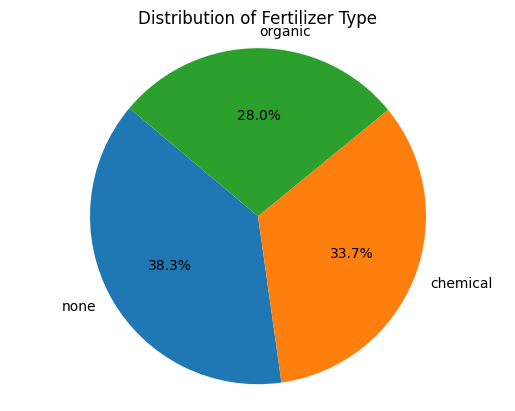

In [14]:
plt.pie(df['Fertilizer_Type'].value_counts().values,
        labels=df['Fertilizer_Type'].value_counts().index,
        autopct='%1.1f%%',
        startangle=140)
plt.title("Distribution of Fertilizer Type")
plt.axis('equal')
plt.show()

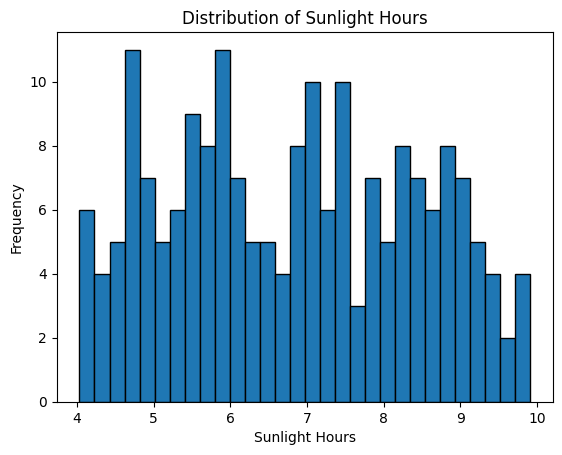

In [15]:
plt.hist(df['Sunlight_Hours'], bins=30, edgecolor='black')
plt.title('Distribution of Sunlight Hours')
plt.xlabel('Sunlight Hours')
plt.ylabel('Frequency')
plt.show()

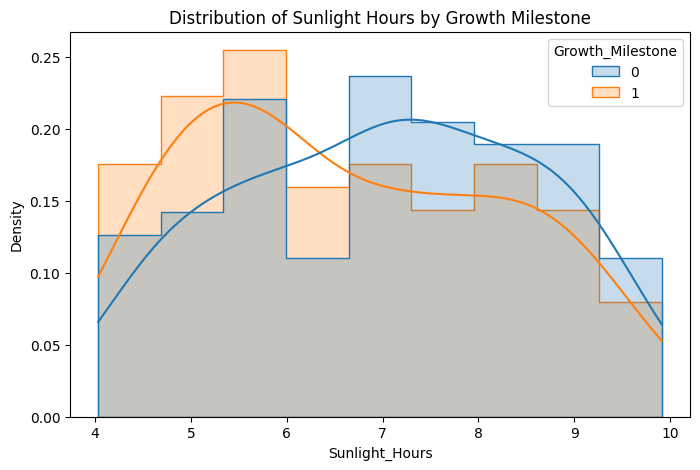

In [16]:
plt.figure(figsize=(8,5))
sns.histplot(
    data=df,
    x='Sunlight_Hours',
    hue='Growth_Milestone',
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)
plt.title('Distribution of Sunlight Hours by Growth Milestone')
plt.show()

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_18572\2475314428.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


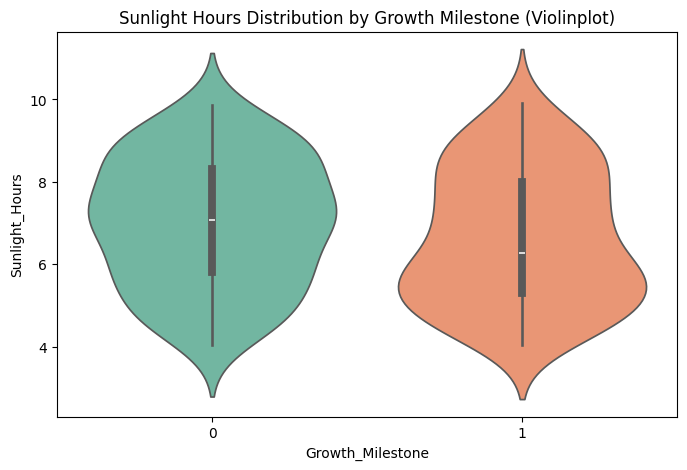

In [17]:
plt.figure(figsize=(8, 5))
sns.violinplot(
    data=df,
    x='Growth_Milestone',
    y='Sunlight_Hours',
    palette='Set2'
    )
plt.title("Sunlight Hours Distribution by Growth Milestone (Violinplot)")
plt.show()

C:\Users\Himanshu\AppData\Local\Temp\ipykernel_18572\3416162055.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


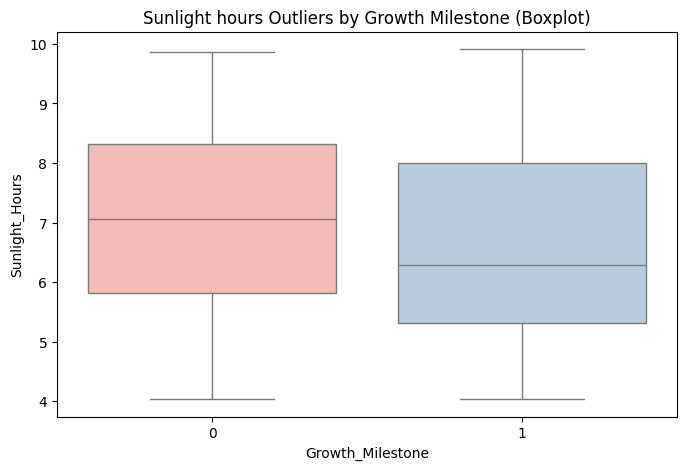

In [18]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    x='Growth_Milestone',
    y='Sunlight_Hours',
    palette='Pastel1'
)
plt.title("Sunlight hours Outliers by Growth Milestone (Boxplot)")
plt.show()

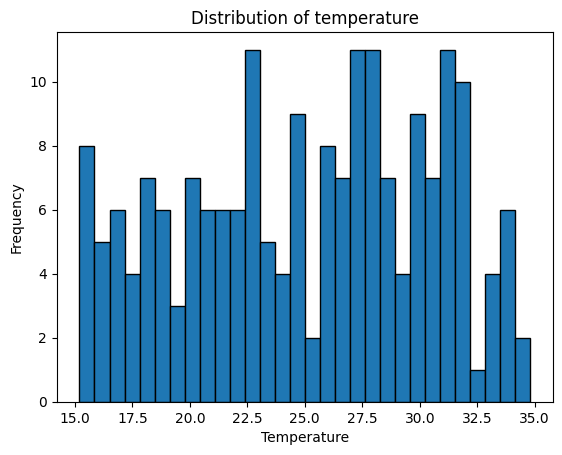

In [19]:
plt.hist(df['Temperature'], bins=30, edgecolor='black')
plt.title('Distribution of temperature')
plt.xlabel('Temperature')
plt.ylabel('Frequency')
plt.show()

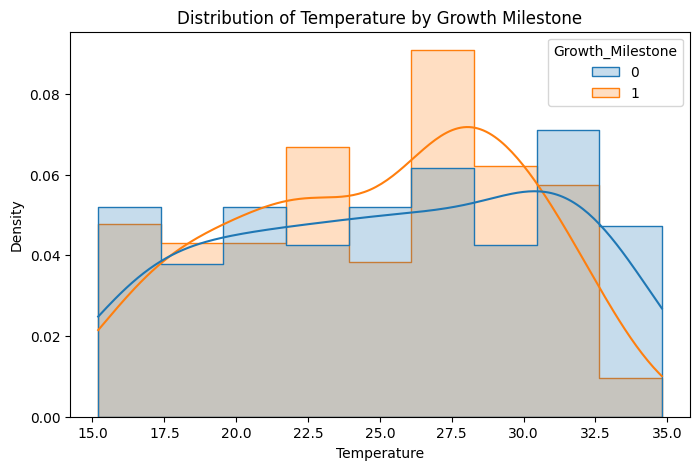

In [20]:
plt.figure(figsize=(8,5))
sns.histplot(
    data=df,
    x='Temperature',
    hue='Growth_Milestone',
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)
plt.title("Distribution of Temperature by Growth Milestone")
plt.show()

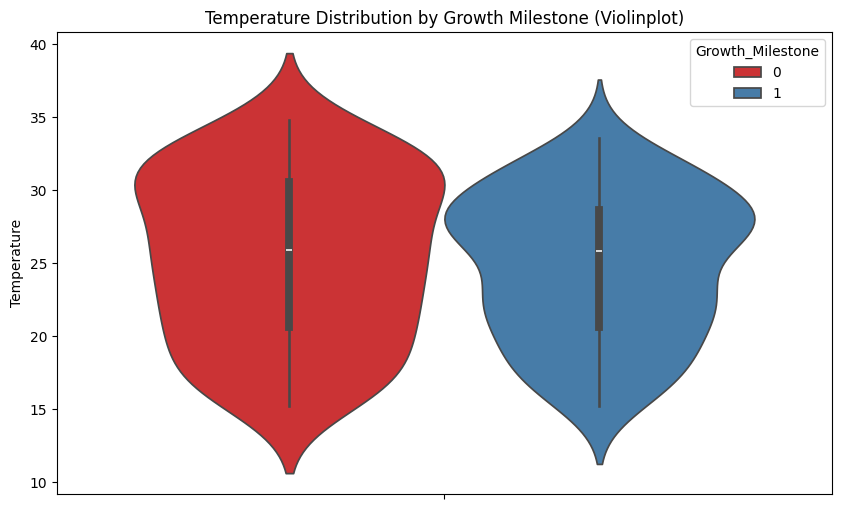

In [21]:
plt.figure(figsize=(10, 6))
sns.violinplot(
    data=df,
    hue='Growth_Milestone',
    y='Temperature',
    palette='Set1'
)
plt.title("Temperature Distribution by Growth Milestone (Violinplot)")
plt.show()

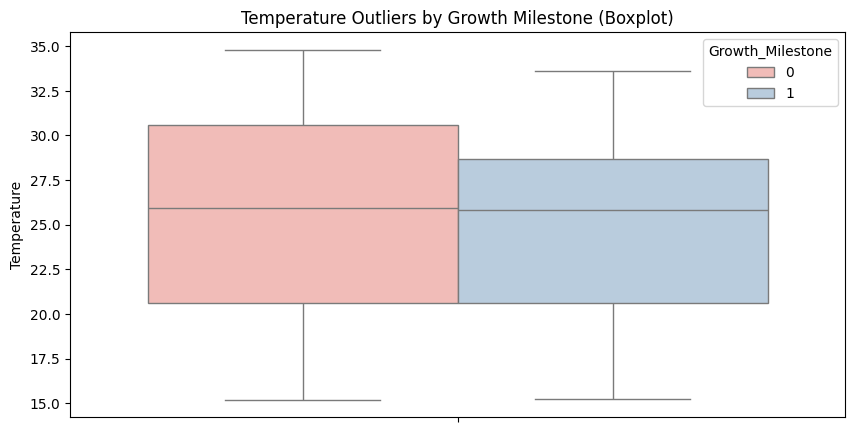

In [22]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    hue='Growth_Milestone',
    y='Temperature',
    palette='Pastel1'
)
plt.title("Temperature Outliers by Growth Milestone (Boxplot)")
plt.show()

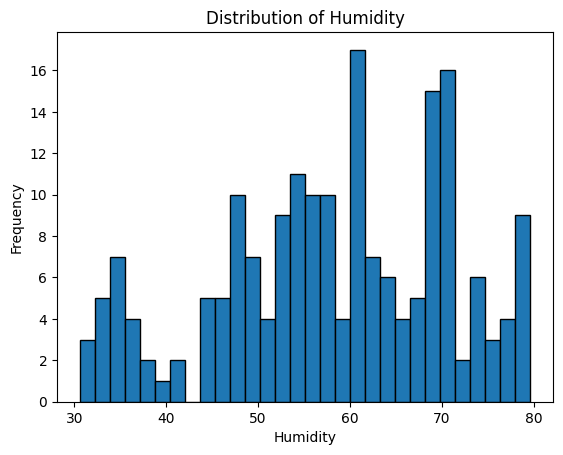

In [23]:
plt.hist(df['Humidity'], bins=30, edgecolor='black')
plt.title('Distribution of Humidity')
plt.xlabel('Humidity')
plt.ylabel('Frequency')
plt.show()

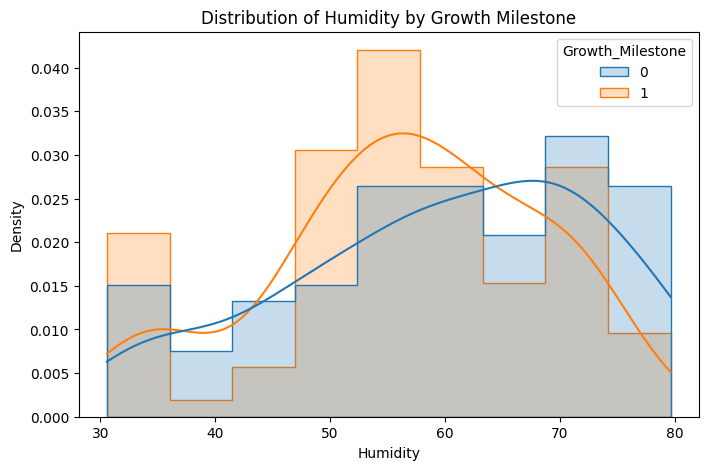

In [24]:
plt.figure(figsize=(8,5))
sns.histplot(
    data=df,
    x='Humidity',
    hue='Growth_Milestone',
    kde=True,
    element='step',
    stat='density',
    common_norm=False
)
plt.title("Distribution of Humidity by Growth Milestone")
plt.show()

<Axes: ylabel='Humidity'>

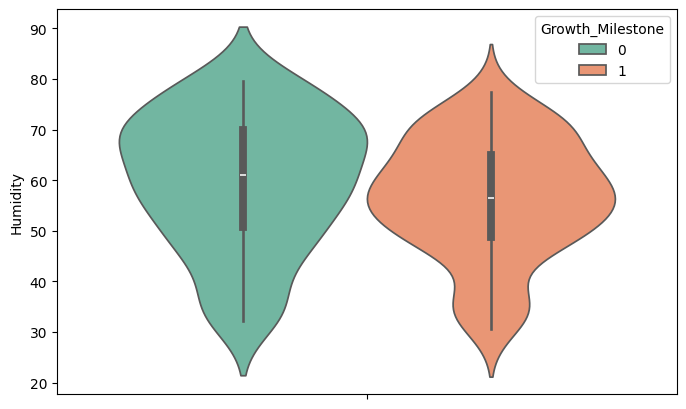

In [25]:
plt.figure(figsize=(8, 5))
sns.violinplot(
    data=df,
    hue='Growth_Milestone',
    y='Humidity',
    palette='Set2'
)

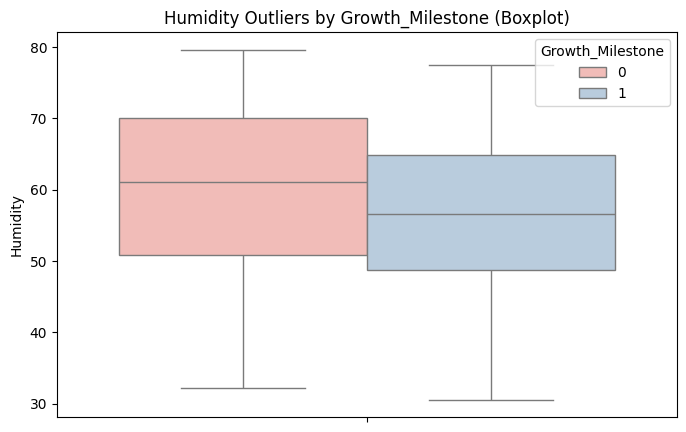

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=df,
    hue='Growth_Milestone',
    y='Humidity',
    palette='Pastel1'
)
plt.title("Humidity Outliers by Growth_Milestone (Boxplot)")
plt.show()

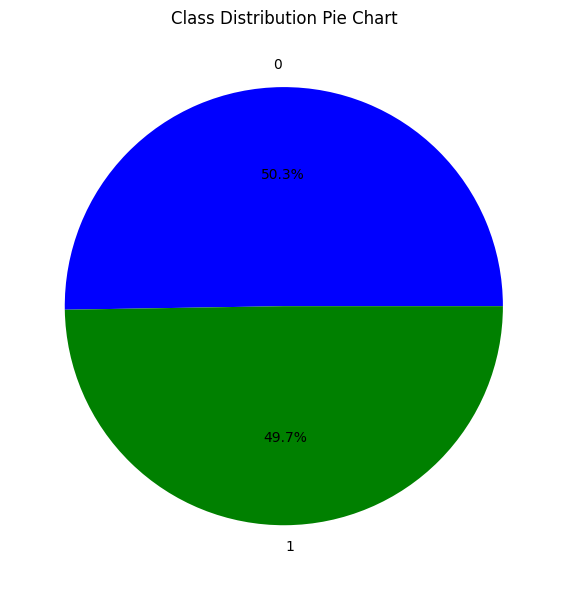

In [27]:
growth_milestone_count = df['Growth_Milestone'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(
    growth_milestone_count,
    labels=growth_milestone_count.index,
    autopct='%1.1f%%',
    colors=['blue', 'green']
)
plt.title('Class Distribution Pie Chart')
plt.tight_layout()
plt.show()

<Figure size 800x600 with 0 Axes>

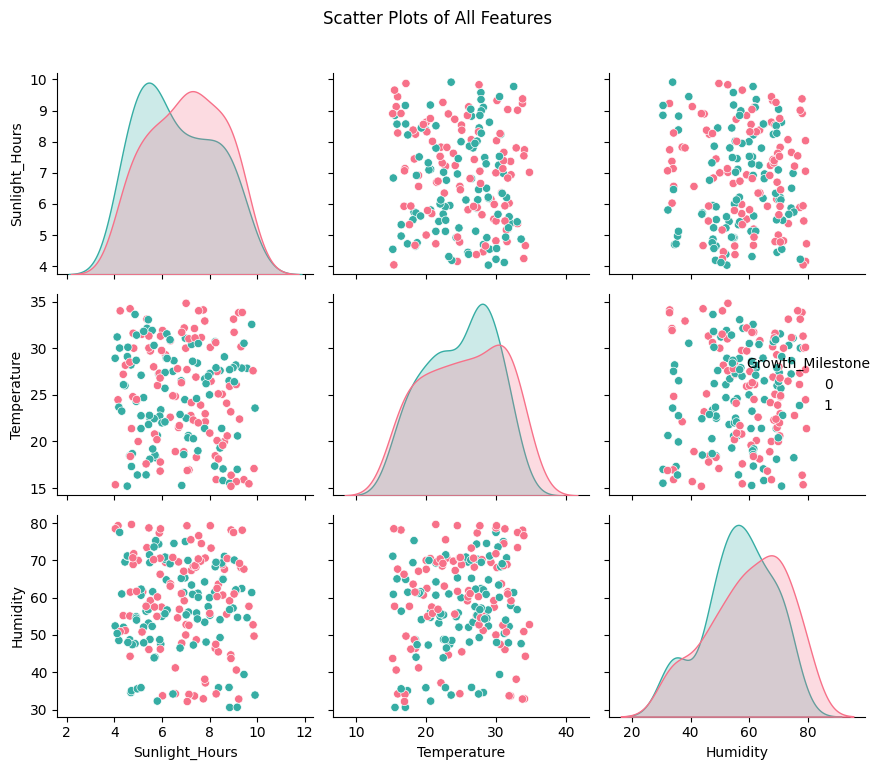

In [28]:
plt.figure(figsize=(8, 6))
sns.pairplot(
    df,
    hue='Growth_Milestone',
    diag_kind='kde',
    palette='husl',

)
plt.suptitle("Scatter Plots of All Features", y=1.02)
plt.tight_layout()
plt.show()

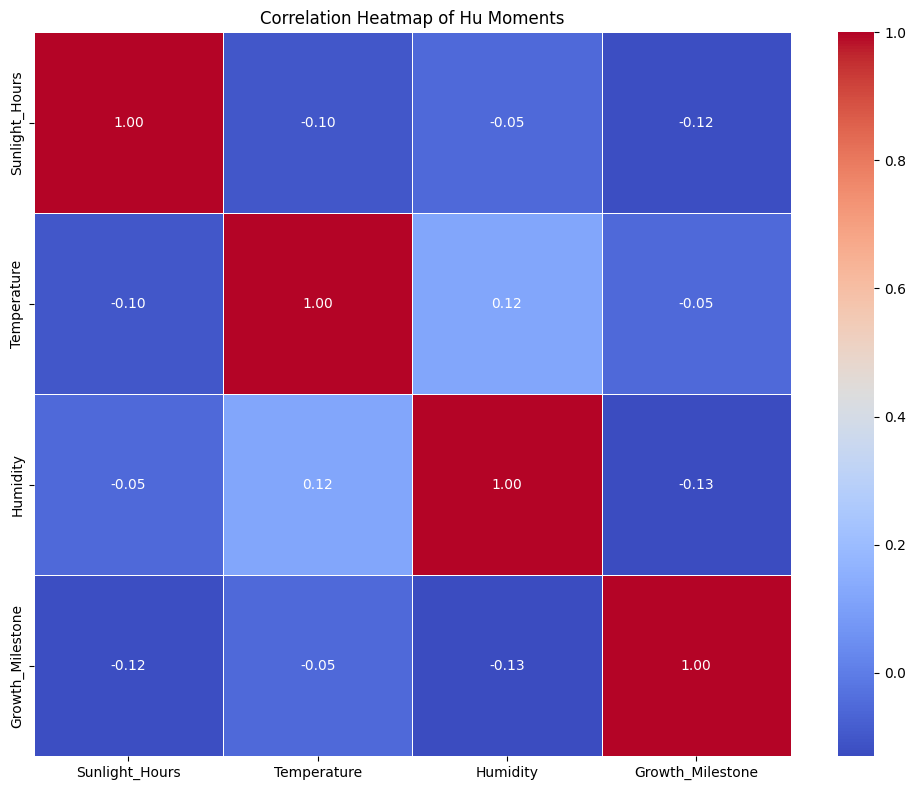

In [29]:
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f', 
    linewidths=.5
)
plt.title('Correlation Heatmap of Hu Moments')
plt.tight_layout()
plt.show()

In [30]:
df['Sunlight_Temperature_Ratio'] = df['Sunlight_Hours'] / df['Temperature']
df['Humidity_Temperature_Ratio'] = df['Humidity'] / df['Temperature']

In [31]:
df

,Soil_Type,Sunlight_Hours,Water_Frequency,Fertilizer_Type,Temperature,Humidity,Growth_Milestone,Sunlight_Temperature_Ratio,Humidity_Temperature_Ratio
0,loam,5.192294,bi-weekly,chemical,31.719602,61.591861,0,0.163694,1.941760
1,sandy,4.033133,weekly,organic,28.919484,52.422276,1,0.139461,1.812697
2,loam,8.892769,bi-weekly,none,23.179059,44.660539,0,0.383655,1.926762
3,loam,8.241144,bi-weekly,none,18.465886,46.433227,0,0.446290,2.514541
4,sandy,8.374043,bi-weekly,organic,18.128741,63.625923,0,0.461921,3.509671
...,...,...,...,...,...,...,...,...,...
188,sandy,5.652000,daily,none,28.000000,70.200000,0,0.201857,2.507143
189,clay,7.528000,weekly,chemical,30.500000,60.100000,1,0.246820,1.970492
190,loam,4.934000,bi-weekly,none,24.500000,61.700000,0,0.201388,2.518367
191,sandy,8.273000,daily,organic,27.900000,69.500000,1,0.296523,2.491039


In [32]:
categorical_cols = ['Soil_Type', 'Water_Frequency', 'Fertilizer_Type']
numerical_cols = ['Sunlight_Hours', 'Temperature', 'Humidity']

In [33]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

In [34]:
X = df.drop('Growth_Milestone', axis=1)
y = df['Growth_Milestone']

In [35]:
X.head()

,Soil_Type,Sunlight_Hours,Water_Frequency,Fertilizer_Type,Temperature,Humidity,Sunlight_Temperature_Ratio,Humidity_Temperature_Ratio
0,loam,5.192294,bi-weekly,chemical,31.719602,61.591861,0.163694,1.941760
1,sandy,4.033133,weekly,organic,28.919484,52.422276,0.139461,1.812697
2,loam,8.892769,bi-weekly,none,23.179059,44.660539,0.383655,1.926762
3,loam,8.241144,bi-weekly,none,18.465886,46.433227,0.446290,2.514541
4,sandy,8.374043,bi-weekly,organic,18.128741,63.625923,0.461921,3.509671


In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [37]:
preprocessor.fit(X_train)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

In [38]:
X_train_prepocessed = preprocessor.transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)

In [39]:
print("Training data shape: ", X_train_prepocessed.shape)
print("Test data shape: ", X_test_preprocessed.shape)

Training data shape:  (154, 12)
Test data shape:  (39, 12)


In [40]:
X_train_prepocessed[0,:]

array([0.10824419, 1.33035234, 0.0727723 , 1.        , 0.        ,
       0.        , 1.        , 0.        , 0.        , 0.        ,
       1.        , 0.        ])

In [41]:
ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
feature_names = list(numerical_cols) + list(ohe_feature_names)

In [42]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_prepocessed)

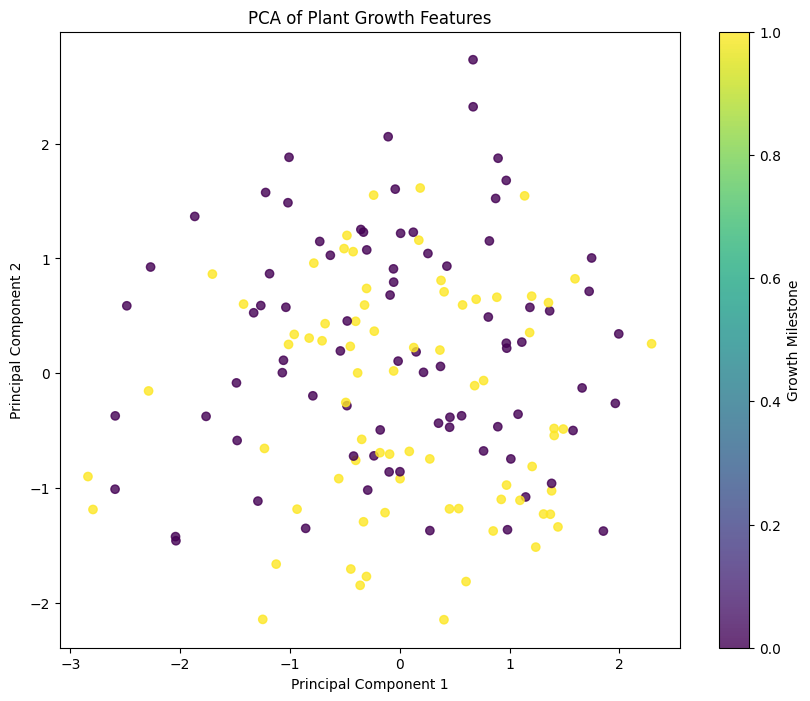

In [43]:
plt.figure(figsize=(10, 8))
plt.scatter(X_pca[:,0], X_pca[:, 1], c=y_train, cmap='viridis', alpha=0.8)
plt.title('PCA of Plant Growth Features')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.colorbar(label='Growth Milestone')
plt.show()

In [44]:
print("1. Support Vector Machine")
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.1, 0.01],
    'kernel': ['rbf', 'poly', 'sigmoid']
}

grid_svm = GridSearchCV(
    SVC(),
    param_grid_svm,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_svm.fit(X_train_prepocessed, y_train)

y_pred_svm = grid_svm.predict(X_test_preprocessed)
print("Best Parameters: ", grid_svm.best_params_)
print("Best Cross-Validation Score", grid_svm.best_score_)
print("Test Accuracy: ", accuracy_score(y_test, y_pred_svm))
print("Classification Report: \n", classification_report(y_test, y_pred_svm))

1. Support Vector Machine
Best Parameters:  {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}
Best Cross-Validation Score 0.6486021505376344
Test Accuracy:  0.5897435897435898
Classification Report: 
               precision    recall  f1-score   support

           0       0.52      0.65      0.58        17
           1       0.67      0.55      0.60        22

    accuracy                           0.59        39
   macro avg       0.60      0.60      0.59        39
weighted avg       0.60      0.59      0.59        39



In [45]:
print("2. Random Forest")
rfc = RandomForestClassifier(random_state=42)
param_grid_rf = {
    'n_estimators': [50, 100, 150],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2', None]
}
grid_rf = GridSearchCV(
    rfc, 
    param_grid_rf,
    cv=5,
    scoring='accuracy',\
    n_jobs=-1
)

grid_rf.fit(X_train_prepocessed, y_train)

y_pred_rf = grid_rf.predict(X_test_preprocessed)
print("Best Parameters: ", grid_rf.best_params_)
print("Best Cross Validation Score: ", grid_rf.best_score_)
print("Test Accuracy: ", accuracy_score(y_test, y_pred_rf))
print("Classification Report\n", classification_report(y_test, y_pred_rf))

2. Random Forest
Best Parameters:  {'max_depth': None, 'max_features': None, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 150}
Best Cross Validation Score:  0.6359139784946237
Test Accuracy:  0.6153846153846154
Classification Report
               precision    recall  f1-score   support

           0       0.55      0.65      0.59        17
           1       0.68      0.59      0.63        22

    accuracy                           0.62        39
   macro avg       0.62      0.62      0.61        39
weighted avg       0.63      0.62      0.62        39



In [46]:
best_rf = grid_rf.best_estimator_
importances = best_rf.feature_importances_
feature_importance = pd.Series(
    importances,
    index=feature_names
).sort_values(ascending=False)
print("Feature Importances: \n")
print(feature_importance)

Feature Importances: 

Humidity                     0.280808
Temperature                  0.255321
Sunlight_Hours               0.221995
Fertilizer_Type_organic      0.069200
Fertilizer_Type_none         0.060573
Soil_Type_loam               0.024183
Water_Frequency_daily        0.021986
Soil_Type_sandy              0.015331
Water_Frequency_bi-weekly    0.014522
Water_Frequency_weekly       0.013295
Soil_Type_clay               0.013063
Fertilizer_Type_chemical     0.009724
dtype: float64


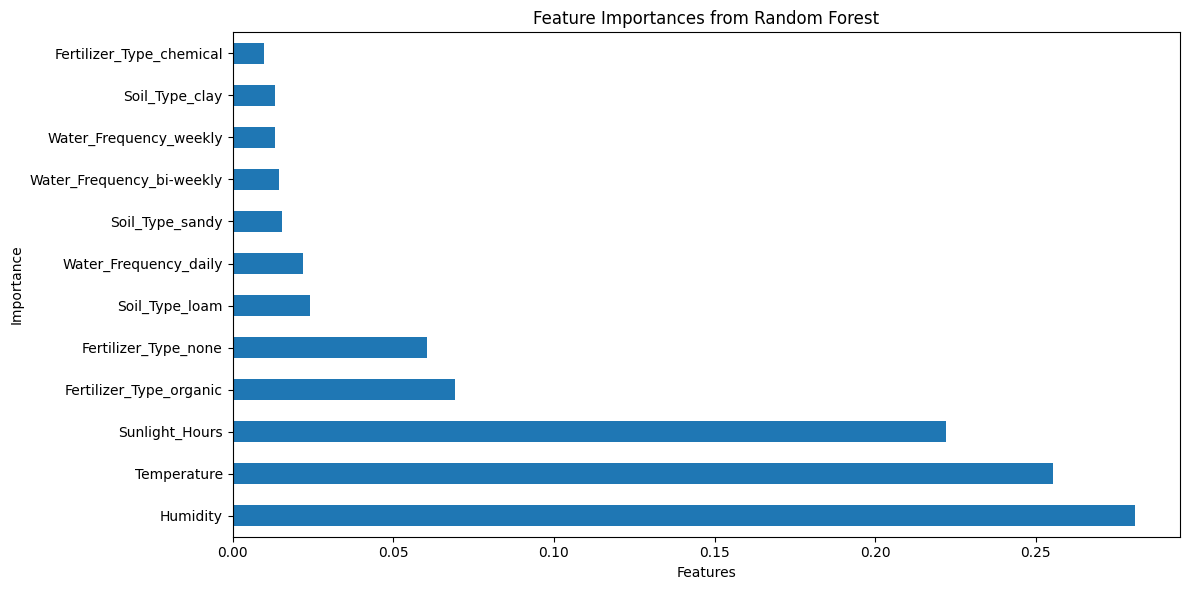

In [47]:
plt.figure(figsize=(12, 6))
feature_importance.plot(kind='barh')
plt.title("Feature Importances from Random Forest")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.tight_layout()
plt.show()

In [48]:
print("3. Logistic Regression")
logreg = LogisticRegression(max_iter=1000, random_state=42)
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['12', '11', 'elasticnet', None],
    'solver': ['lbfgs', 'liblinear', 'saga']
}
grid_lr = GridSearchCV(
    logreg,
    param_grid_lr,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_lr.fit(X_train_prepocessed, y_train)

y_pred_lr = grid_lr.predict(X_test_preprocessed)
print("Best Parameters: ", grid_lr.best_params_)
print("Best Cross Validation Score: ", grid_lr.best_score_)
print("Test Accuracy: ", accuracy_score(y_test, y_pred_lr))
print("Classification Report:\n", classification_report(y_test, y_pred_lr))

3. Logistic Regression
Best Parameters:  {'C': 10, 'penalty': 'elasticnet', 'solver': 'saga'}
Best Cross Validation Score:  0.6098924731182795
Test Accuracy:  0.5641025641025641
Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.59      0.54        17
           1       0.63      0.55      0.59        22

    accuracy                           0.56        39
   macro avg       0.57      0.57      0.56        39
weighted avg       0.57      0.56      0.57        39



d:\anaconda3\envs\mlenv\Lib\site-packages\sklearn\model_selection\_validation.py:490: FitFailedWarning: 
225 fits failed out of a total of 300.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
19 fits failed with the following error:
Traceback (most recent call last):
  File "d:\anaconda3\envs\mlenv\Lib\site-packages\sklearn\model_selection\_validation.py", line 833, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "d:\anaconda3\envs\mlenv\Lib\site-packages\sklearn\base.py", line 1329, in wrapper
    estimator._validate_params()
  File "d:\anaconda3\envs\mlenv\Lib\site-packages\sklearn\base.py", line 492, in _validate_params
    validate_parameter_constraints(
  File "d:\anaconda3\envs\mlenv\Lib\site-packages\skl

In [49]:
print("4. Gradient Boosting")
gb = GradientBoostingClassifier(random_state=42)
param_grid_gb = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'min_samples_split': [2, 5],
    'subsample': [0.8, 1.0]
}
grid_gb = GridSearchCV(
    gb,
    param_grid_gb,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_gb.fit(X_train_prepocessed, y_train)

y_pred_gb = grid_gb.predict(X_test_preprocessed)
print("Best Parameters: ", grid_gb.best_params_)
print("Best Cross-Validation Score: ", grid_gb.best_score_)
print("Test Accuracy: ", accuracy_score(y_test, y_pred_gb))
print("Classification Report: \n",classification_report(y_test, y_pred_gb))

4. Gradient Boosting
Best Parameters:  {'learning_rate': 0.01, 'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 200, 'subsample': 0.8}
Best Cross-Validation Score:  0.6488172043010753
Test Accuracy:  0.5641025641025641
Classification Report: 
               precision    recall  f1-score   support

           0       0.50      0.53      0.51        17
           1       0.62      0.59      0.60        22

    accuracy                           0.56        39
   macro avg       0.56      0.56      0.56        39
weighted avg       0.57      0.56      0.57        39



In [51]:
print("===== MODEL COMPARISON =====\n")
models = {
    'SVM': grid_svm.best_estimator_,
    'Random Forest': grid_rf.best_estimator_,
    'Logistic Regression': grid_lr.best_estimator_,
    'Gradient Boosting': grid_gb.best_estimator_
}

===== MODEL COMPARISON =====



In [52]:
cv_results = {}
for name, model in models.items():
    cv_scores = cross_val_score(
        model,
        X_train_prepocessed,
        y_train,
        cv=5,
        scoring='accuracy'
    )
    cv_results[name] = {
        'CV Mean': cv_scores.mean(),
        'CV Std': cv_scores.std(),
        'Test Accuracy': accuracy_score(y_test, model.predict(X_test_preprocessed))
    }

cv_df = pd.DataFrame(cv_results).T
print(cv_df)

d:\anaconda3\envs\mlenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\anaconda3\envs\mlenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\anaconda3\envs\mlenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set

                      CV Mean    CV Std  Test Accuracy
SVM                  0.648602  0.076283       0.589744
Random Forest        0.635914  0.094059       0.615385
Logistic Regression  0.609892  0.061275       0.564103
Gradient Boosting    0.648817  0.085172       0.564103


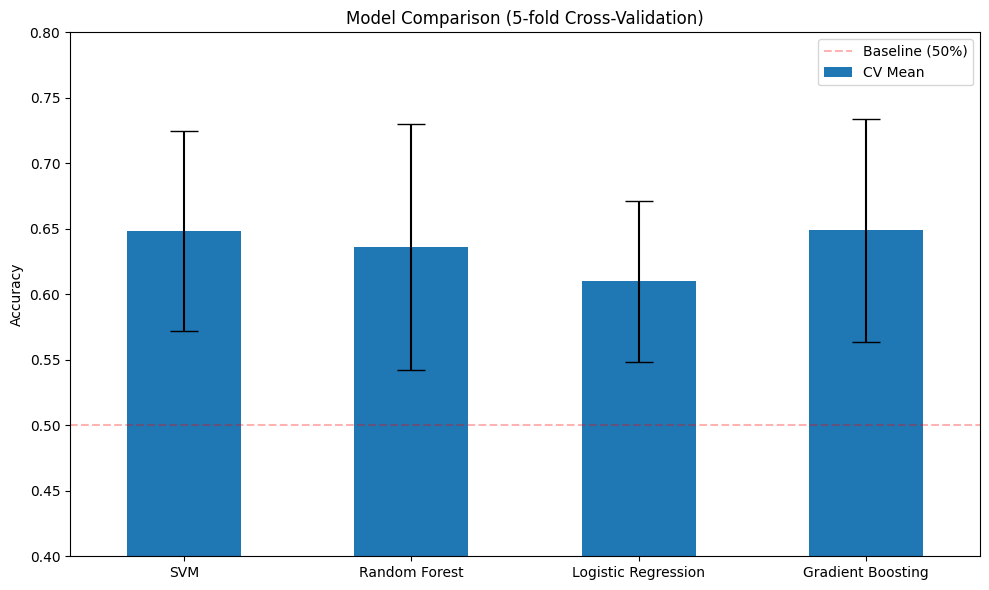

In [56]:
plt.figure(figsize=(10, 6))
cv_df['CV Mean'].plot(
    kind='bar',
    yerr=cv_df['CV Std'],
    capsize=10,
    rot=0
)
plt.axhline(
    y=0.5,
    color='r',
    linestyle='--',
    alpha=0.3,
    label='Baseline (50%)'
)
plt.title('Model Comparison (5-fold Cross-Validation)')
plt.ylabel('Accuracy')
plt.ylim(0.4, 0.8)
plt.legend()
plt.tight_layout()
plt.show()

In [57]:
print("==== CONCLUSION ====\n")
best_model = cv_df['Test Accuracy'].idxmax()
print(f"The best performing model is {best_model} with {cv_df.loc[best_model, 'Test Accuracy']:.4f} test accruacy")

==== CONCLUSION ====

The best performing model is Random Forest with 0.6154 test accruacy
